In [1]:
import os
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.distributions.normal import Normal
import gymnasium as gym

In [2]:
class Policy_Network(nn.Module):
    def __init__(self, obs_space_dims: int, action_space_dims: int):
        super().__init__()
        hidden_space1 = 16
        hidden_space2 = 32
        self.shared_net = nn.Sequential(
            nn.Linear(obs_space_dims, hidden_space1),
            nn.Tanh(),
            nn.Linear(hidden_space1, hidden_space2),
            nn.Tanh(),
        )
        self.policy_mean_net = nn.Sequential(nn.Linear(hidden_space2, action_space_dims))
        self.policy_stddev_net = nn.Sequential(nn.Linear(hidden_space2, action_space_dims))

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        shared_features = self.shared_net(x.float())
        action_means = self.policy_mean_net(shared_features)
        action_stddevs = torch.log(1 + torch.exp(self.policy_stddev_net(shared_features)))
        return action_means, action_stddevs



In [3]:
class Value_Network(nn.Module):
    def __init__(self, obs_space_dims: int):
        super().__init__()
        hidden_space1 = 16
        hidden_space2 = 32
        self.net = nn.Sequential(
            nn.Linear(obs_space_dims, hidden_space1),
            nn.Tanh(),
            nn.Linear(hidden_space1, hidden_space2),
            nn.Tanh(),
            nn.Linear(hidden_space2, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x.float()).squeeze(-1)

In [7]:
class REINFORCE_Baseline:
    def __init__(self, obs_space_dims: int, action_space_dims: int):
        self.learning_rate = 1e-4     
        self.value_learning_rate = 1e-3  
        self.gamma = 0.99
        self.eps = 1e-6

        self.probs = []
        self.rewards = []
        self.states = []   

        self.net = Policy_Network(obs_space_dims, action_space_dims)
        self.value_net = Value_Network(obs_space_dims)   

        self.optimizer = torch.optim.AdamW(self.net.parameters(), lr=self.learning_rate)
        self.value_optimizer = torch.optim.AdamW(self.value_net.parameters(), lr=self.value_learning_rate)
        

    def sample_action(self, state: np.ndarray) -> float:
        state_t = torch.from_numpy(state).float().unsqueeze(0)
        action_means, action_stddevs = self.net(state_t)

        distrib = Normal(action_means[0] + self.eps, action_stddevs[0] + self.eps)
        action = distrib.sample()
        prob = distrib.log_prob(action)

        self.probs.append(prob)
        self.states.append(state_t)  
        return action.numpy()

    def update(self):
        running_g = 0
        gs = []
        for R in self.rewards[::-1]:
            running_g = R + self.gamma * running_g
            gs.insert(0, running_g)

        returns = torch.tensor(gs, dtype=torch.float32)
        states = torch.cat(self.states, dim=0)          
        values = self.value_net(states)                  

        advantages = (returns - values).detach()          
        log_probs = torch.stack(self.probs).squeeze(dim=-1)

        policy_loss = -torch.sum(log_probs * advantages)
        self.optimizer.zero_grad()
        policy_loss.backward()
        self.optimizer.step()

        value_loss = torch.nn.functional.mse_loss(values, returns)
        self.value_optimizer.zero_grad()
        value_loss.backward()
        self.value_optimizer.step()

        self.probs = []
        self.rewards = []
        self.states = []



In [10]:
def run(total_num_episodes: int = 5000, seeds=(1, 2, 3, 5, 8)):
    out_dir: str = "../results"
    plot_dir: str = f"{out_dir}/plots"
    os.makedirs(out_dir, exist_ok=True)
    env = gym.make("InvertedPendulum-v4")
    wrapped_env = gym.wrappers.RecordEpisodeStatistics(env, 50)

    obs_space_dims = env.observation_space.shape[0]
    action_space_dims = env.action_space.shape[0]
    rewards_over_seeds = []

    for seed in seeds:
        torch.manual_seed(seed)
        random.seed(seed)
        np.random.seed(seed)

        agent = REINFORCE_Baseline(obs_space_dims, action_space_dims)
        reward_over_episodes = []

        for episode in range(total_num_episodes):
            obs, info = wrapped_env.reset(seed=seed if episode == 0 else None)
            done = False
            while not done:
                action = agent.sample_action(obs)
                obs, reward, terminated, truncated, info = wrapped_env.step(action)
                agent.rewards.append(reward)
                done = terminated or truncated

            reward_over_episodes.append(wrapped_env.return_queue[-1])
            agent.update()

            if episode % 1000 == 0:
                avg_reward = int(np.mean(wrapped_env.return_queue))
                print(f"[REINFORCE+Baseline][seed {seed}] Episode:", episode, "Average Reward:", avg_reward)

        rewards_over_seeds.append(reward_over_episodes)
        np.save(os.path.join(out_dir, f"reinforce_baseline_seed{seed}.npy"), np.array(reward_over_episodes, dtype=np.float32))

    np.save(os.path.join(out_dir, "reinforce_baseline_all_seeds.npy"), np.array(rewards_over_seeds, dtype=np.float32))

    # Plotting the results
    df = pd.DataFrame(rewards_over_seeds).melt()
    df.rename(columns={"variable": "episodes", "value": "reward"}, inplace=True)
    
    sns.set(style="darkgrid", context="talk", palette="rainbow")
    plt.figure(figsize=(10, 6))
    sns.lineplot(x="episodes", y="reward", data=df).set(title="REINFORCE with Baseline for InvertedPendulum-v4")
    plt.show()
    plt.savefig(os.path.join(out_dir, "reinforce_baseline_plot.png"))

    return rewards_over_seeds

/Users/pemithw/Desktop/MSc/Sem 2/Advanced AI/Assignments/Individual Assignment/.venv/lib/python3.12/site-packages/gymnasium/envs/registration.py:513: DeprecationWarning: WARN: The environment InvertedPendulum-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(


[REINFORCE+Baseline][seed 1] Episode: 0 Average Reward: 5
[REINFORCE+Baseline][seed 1] Episode: 1000 Average Reward: 68
[REINFORCE+Baseline][seed 1] Episode: 2000 Average Reward: 138
[REINFORCE+Baseline][seed 1] Episode: 3000 Average Reward: 270
[REINFORCE+Baseline][seed 1] Episode: 4000 Average Reward: 865
[REINFORCE+Baseline][seed 2] Episode: 0 Average Reward: 980
[REINFORCE+Baseline][seed 2] Episode: 1000 Average Reward: 26
[REINFORCE+Baseline][seed 2] Episode: 2000 Average Reward: 163
[REINFORCE+Baseline][seed 2] Episode: 3000 Average Reward: 813
[REINFORCE+Baseline][seed 2] Episode: 4000 Average Reward: 986
[REINFORCE+Baseline][seed 3] Episode: 0 Average Reward: 978
[REINFORCE+Baseline][seed 3] Episode: 1000 Average Reward: 29
[REINFORCE+Baseline][seed 3] Episode: 2000 Average Reward: 687
[REINFORCE+Baseline][seed 3] Episode: 3000 Average Reward: 972
[REINFORCE+Baseline][seed 3] Episode: 4000 Average Reward: 991
[REINFORCE+Baseline][seed 5] Episode: 0 Average Reward: 926
[REINFORC

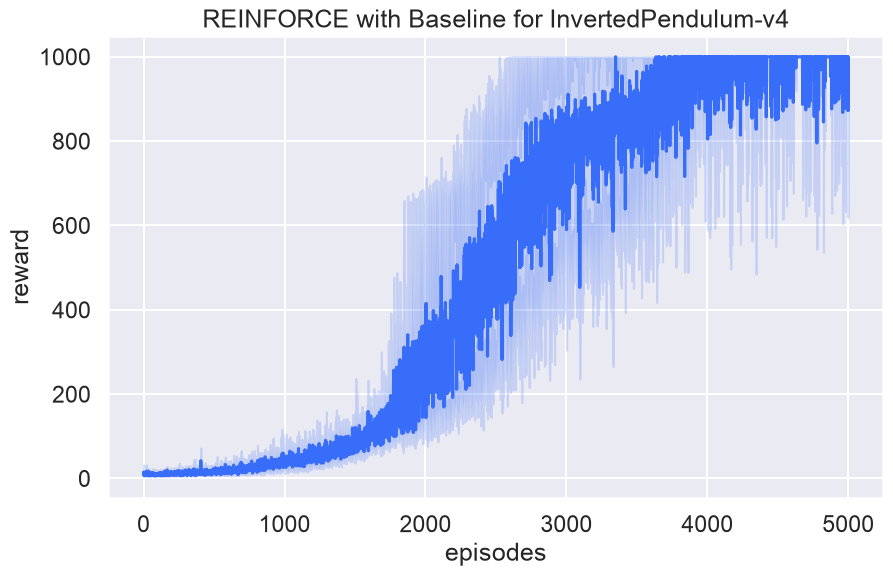

<Figure size 640x480 with 0 Axes>

In [11]:
# Execute the training right inside the notebook
results = run(total_num_episodes=5000, seeds=(1, 2, 3, 5, 8))